# 08 · Airport upkeep (a case study) and what a layover can be used for
Two supporting analyses, both labelled as such in the deck.

**Upkeep / renovation.** There is no public "condition rating" for airports. FAA Airport
Improvement Program grant histories (https://www.faa.gov/airports/aip/grant_histories) record
capital investment, but a documented 2025 construction event lets us measure the effect directly:
Newark's runway 4L-22R was closed for a $121M rehabilitation from **15 April to 2 June 2025**
(Port Authority / FAA; reopened 13 days early), with weeknight closures continuing afterwards.
The same spring also saw air-traffic-control staffing problems at Newark, so the effect below is
"runway closure plus ATC trouble", not construction alone.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import prep, style
from style import INK, GREY, ACCENT, GOOD, BLUE, AMBER, PCT
style.use()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.3f}".format, "display.max_colwidth", 120)

f = pd.read_parquet(prep.PROCESSED / "flights_full.parquet", columns=["FL_DATE", "ORIGIN", "DEST", "disrupted", "severe", "CANCELLED"])
f["week"] = f.FL_DATE.dt.to_period("W").dt.start_time
ny = {"EWR": "Newark (runway closed Apr 15 - Jun 2)", "JFK": "JFK", "LGA": "LaGuardia"}
w = f[f.ORIGIN.isin(ny)].groupby(["week", "ORIGIN"], observed=True).agg(disrupted=("disrupted", "mean"), cancelled=("CANCELLED", "mean"), n=("disrupted", "size")).reset_index()
w["ORIGIN"] = w.ORIGIN.astype(str)

,EWR,JFK+LGA
disrupted before,0.211,0.237
disrupted during closure,0.346,0.235
cancelled before,0.009,0.014
cancelled during closure,0.039,0.009


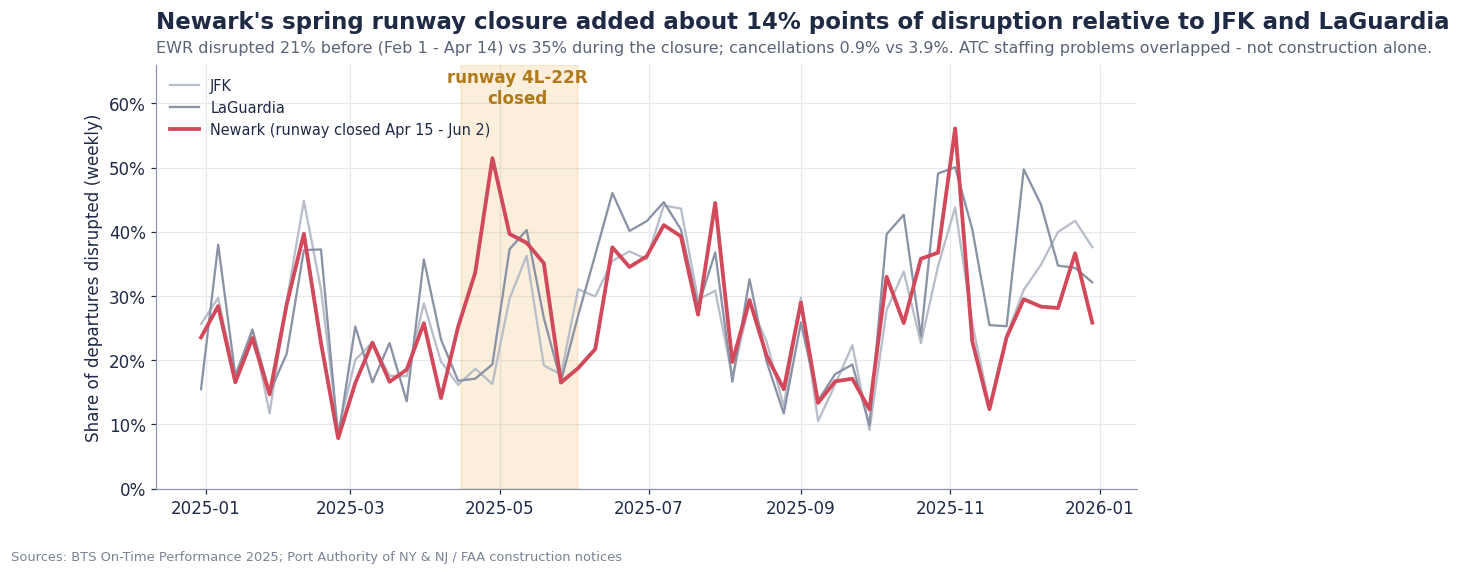

In [2]:
fig, ax = plt.subplots(figsize=(11.5, 5))
for a, col, lw in [("JFK", GREY, 1.5), ("LGA", "#8A93A6", 1.5), ("EWR", ACCENT, 2.5)]:
    d = w[w.ORIGIN == a]
    ax.plot(d.week, d.disrupted, color=col, lw=lw, label=ny[a])
ax.axvspan(pd.Timestamp("2025-04-15"), pd.Timestamp("2025-06-02"), color=AMBER, alpha=.18)
ax.set_ylim(0, .66)
ax.text(pd.Timestamp("2025-05-08"), .60, "runway 4L-22R\nclosed", ha="center", color="#B07A1A", fontweight="bold")
ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Share of departures disrupted (weekly)"); ax.legend(loc="upper left", fontsize=9.5)
pre = f[(f.ORIGIN == "EWR") & f.FL_DATE.between("2025-02-01", "2025-04-14")]; dur = f[(f.ORIGIN == "EWR") & f.FL_DATE.between("2025-04-15", "2025-06-02")]
oth_pre = f[f.ORIGIN.isin(["JFK", "LGA"]) & f.FL_DATE.between("2025-02-01", "2025-04-14")]; oth_dur = f[f.ORIGIN.isin(["JFK", "LGA"]) & f.FL_DATE.between("2025-04-15", "2025-06-02")]
did = (dur.disrupted.mean() - pre.disrupted.mean()) - (oth_dur.disrupted.mean() - oth_pre.disrupted.mean())
style.titled(ax, f"Newark's spring runway closure added about {did:.0%} points of disruption relative to JFK and LaGuardia",
             f"EWR disrupted {pre.disrupted.mean():.0%} before (Feb 1 - Apr 14) vs {dur.disrupted.mean():.0%} during the closure; cancellations {pre.CANCELLED.mean():.1%} vs {dur.CANCELLED.mean():.1%}. ATC staffing problems overlapped - not construction alone.")
style.save(fig, "26_newark_construction", "Sources: BTS On-Time Performance 2025; Port Authority of NY & NJ / FAA construction notices");
ev = pd.DataFrame({"EWR": [pre.disrupted.mean(), dur.disrupted.mean(), pre.CANCELLED.mean(), dur.CANCELLED.mean()],
                   "JFK+LGA": [oth_pre.disrupted.mean(), oth_dur.disrupted.mean(), oth_pre.CANCELLED.mean(), oth_dur.CANCELLED.mean()]},
                  index=["disrupted before", "disrupted during closure", "cancelled before", "cancelled during closure"])
ev.to_csv(prep.TABLES / "newark_event_study.csv")
ev

**Policy implication:** before booking tight connections or time-critical trips through a hub,
the travel desk checks the FAA's quarterly airport construction notices
(https://www.faa.gov/air_traffic/publications/construction) and treats hubs with active runway work
like weather-fragile hubs - longer buffer, or route around. This is a watch-list rule, not a
ranking of airports by condition: grant histories measure spending, not state of repair.

## What can a traveler actually do with a layover?
The recommended minimum layover is 90 minutes (notebook 05). Deplaning, walking and boarding
take roughly 45-50 of those, leaving **~40 usable minutes** - enough for a lounge, a meal or a
walk, not a workout. Amenities below were looked up on 6 Nov 2026 from the sources shown; several
fitness sources are from 2018 and must be re-checked before they go on a slide.

In [3]:
am = pd.read_csv(prep.EXTERNAL / "hub_amenities.csv")
hub = pd.read_csv(prep.TABLES / "hub_ranking.csv", index_col=0)
cur = pd.read_csv(prep.TABLES / "layover_curve.csv", index_col=0)
usable = cur.loc[90, "avg_layover"] - 50
print(f"Average actual layover under the 90-minute rule: {cur.loc[90, 'avg_layover']:.0f} min -> about {usable:.0f} usable minutes after deplaning, walking and boarding.")
tbl = am[am.hub != "ALL"].groupby("hub").agg(rest=("type", lambda s: ", ".join(am.loc[s.index, "amenity"][s == "rest"])), fitness=("type", lambda s: ", ".join(am.loc[s.index, "amenity"][s == "fitness"])))
tbl = tbl.join(hub[["severe", "misconnect"]]).sort_values("severe")
tbl.rename(columns={"severe": "one-stop trips an hour late", "misconnect": "missed connection"}).to_csv(prep.TABLES / "hub_amenities_summary.csv")
tbl

Average actual layover under the 90-minute rule: 169 min -> about 119 usable minutes after deplaning, walking and boarding.


,rest,fitness,severe,misconnect
hub,,,,
SLC,Minute Suites,,0.094,0.030
SFO,,Yoga rooms,0.109,0.041
IAH,Minute Suites,,0.135,0.036
DTW,Minute Suites,,0.136,0.033
ATL,Minute Suites,,0.140,0.038
DEN,,Yoga on the Fly,0.142,0.033
CLT,Minute Suites,,0.152,0.040
ORD,,Yoga room,0.168,0.046
EWR,Minute Suites,,0.188,0.049


Suggested, assumption-labelled policy: a lounge day pass or meal credit on **approved** connections
(90+ min through a low-risk hub) and automatically on any 2h+ delay (notebook 07 sizes the budget).
Measured with a traveler-satisfaction question, not with health claims the data cannot support.